In [3]:
#Lab 5.1 — Self-Attention & Multi-Head Attention
#1. Toy seequence input 
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)

seq_len, d_model = 5, 4

x = torch.randn(1, seq_len, d_model)

print("Input Shape:", x.shape)
print("Input Tensor:\n", x)

Input Shape: torch.Size([1, 5, 4])
Input Tensor:
 tensor([[[-1.1258, -1.1524, -0.2506, -0.4339],
         [ 0.5988, -1.5551, -0.3414,  1.8530],
         [ 0.4681, -0.1577,  1.4437,  0.2660],
         [ 1.3894,  1.5863,  0.9463, -0.8437],
         [ 0.9318,  1.2590,  2.0050,  0.0537]]])


In [7]:
#2. Scaled dot-production attention
import torch
import torch.nn.functional as F

# Define attention function
def attention(Q, K, V):

    # Calculate attention scores
    scores = (Q @ K.transpose(-2, -1)) / (Q.size(-1) ** 0.5)

    # Apply softmax to calculate attention weights
    weights = F.softmax(scores, dim=-1)

    # Calculate attention output
    return weights @ V, weights


# Assign Query, Key, and Value
Q, K, V = x, x, x

# Apply attention
out, w = attention(Q, K, V)

# Display output
print("Attention output shape:", out.shape)
print("Attention weights shape:", w.shape)

Attention output shape: torch.Size([1, 5, 4])
Attention weights shape: torch.Size([1, 5, 5])


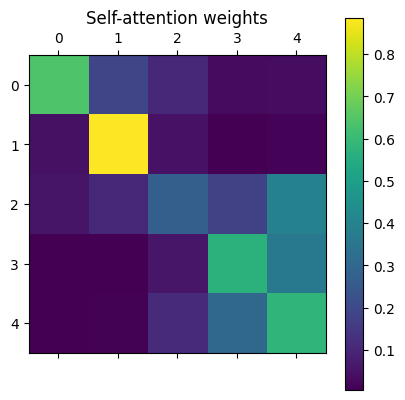

In [11]:
#3. Visualize weights
import matplotlib.pyplot as plt
plt.matshow(w[0].detach().cpu().numpy())
plt.title("Self-attention weights")
plt.colorbar()
plt.show()

In [13]:
#4. Multi-Head Attention module
mha = nn.MultiheadAttention(embed_dim=d_model, num_heads=2, batch_first=True)
out, weights = mha(x, x, x)
print("MHA out shape:", out.shape)
print("Attention weights shape:", weights.shape)

MHA out shape: torch.Size([1, 5, 4])
Attention weights shape: torch.Size([1, 5, 5])
